# Data-Driven Inverse Design of the Injection Concentration in CRTM
### Surrogate inverse model: Gaussian-process data + PCA + MLP

## Introduction

**Compression Resin Transfer Molding (CRTM)** is a variant of Resin Transfer Molding used to manufacture composite parts. A dry fibrous preform is placed in a partially closed mould, the resin is injected into the gap above the preform, and the mould is then closed: the compression drives the resin through the thickness of the reinforcement. Compared with conventional RTM, filling is faster and requires lower injection pressure.

In this work the resin is loaded with **particles**. As the suspension flows through the preform, part of the particles is retained by the fibres (filtration). The final particle distribution in the part, $Q(x)$, therefore depends on the history of the injected concentration $C_0(t)$. Controlling $C_0(t)$ makes it possible to produce **functionally graded (FG) materials**, whose particle content varies along the part in a prescribed way.

**Inverse problem.** Given a target distribution $Q^{\star}(x)$, find the injection profile $C_0(t)$ such that the process yields $Q(x) \approx Q^{\star}(x)$.

**Approach.** Instead of coupling a forward solver (or a forward surrogate) with an optimisation loop, we learn the **inverse map directly**:
$$
\mathcal{G}_\theta : Q(x) \;\longmapsto\; C_0(t).
$$
Once trained, the network returns $C_0$ for any new target in a single forward pass, with no iterative optimisation at inference.

**Data.** The training set is built from process simulations in which the injection profiles $C_0(t)$ are sampled from **Gaussian processes** with a mixed covariance kernel and random correlation lengths, which provides a rich and diverse family of injection histories.

**Pipeline.**
$$
Q \;\xrightarrow{\text{StandardScaler}}\; \xrightarrow{\text{PCA } (k_x)}\; \xrightarrow{\text{MLP}}\; \xrightarrow{\text{PCA}^{-1} (k_y)}\; \xrightarrow{\text{StandardScaler}^{-1}}\; C_0
$$

**Outline.**
1. Setup
2. Data loading
3. Target profiles
4. Preprocessing: scaling and PCA
5. Network architecture and training
6. Evaluation on the test set
7. Inverse design for the target profiles
8. Validation by re-simulation
9. Comparison with the nearest neighbour of the dataset
10. Conclusion

## 1. Setup

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # silences a joblib warning on Windows

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, callbacks, regularizers

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.decomposition import PCA

# ==============================
# CONFIGURATION
# ==============================
tf.random.set_seed(42)
np.random.seed(42)

DATA_DIR  = Path("data")                    # training data
RESIM_DIR = DATA_DIR / "resimulated"        # Q obtained by simulating the predicted C_0
PRED_DIR  = Path("results") / "predicted_C0"
MODEL_DIR = Path("models")
FIG_DIR   = Path("figures")
for d in (PRED_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 2. Data Loading

The simulations are loaded from two text files in `data/` (one simulation per row):
- `quantite_particules_donneesGP0.txt` → `Q_p`: final particle distribution $Q(x)$ — shape $(1000, 301)$, $x \in [0,1]$
- `ConcentrationIGP0.txt` → `C_0`: injection concentration $C_0(t)$ — shape $(1000, 242)$, normalised time $t \in [0,1]$

The $C_0$ profiles are generated by Gaussian processes (mixed covariance, random correlation lengths).

In [2]:
C_0 = np.loadtxt(DATA_DIR / "ConcentrationIGP0.txt", delimiter=',')
Q_p = np.loadtxt(DATA_DIR / "quantite_particules_donneesGP0.txt", delimiter=',')
print("C_0:", C_0.shape, "| Q_p:", Q_p.shape)

## 3. Target Profiles

Six target distributions are considered on $x \in [0,1]$, with $c_{\max}=0.15$ and $c_{\min}=0.075$:

| Name | Definition | Description |
|---|---|---|
| UD | $c_{\max}$ | uniform distribution |
| FG-O | $(c_{\max}-c_{\min})\sin(\pi x)+c_{\min}$ | maximum at the centre |
| FG-X | $(c_{\max}-c_{\min})(1-\sin(\pi x))+c_{\min}$ | maxima at both ends |
| FG-XO | $\tfrac12\left[(c_{\max}+c_{\min})+(c_{\max}-c_{\min})\cos(3\pi x)\right]$ | oscillating, maxima at $x=0$ and $x=2/3$ |
| FG-OX | $\tfrac12(c_{\max}-c_{\min})\sin\!\left(3\pi(x+\tfrac12)\right)+1.5\,c_{\min}$ | oscillating, maxima at $x=1/3$ and $x=1$ |
| FG-NI | piecewise linear: $0.20 \rightarrow 0.10$ between $x=1/3$ and $x=2/3$ | non-smooth gradient |

A single dictionary `targets` links each name to its exact profile and to the files of predicted $C_0$ and re-simulated $Q$.

In [3]:
x = np.linspace(0, 1, 301)   # space grid of Q
t = np.linspace(0, 1, 242)   # normalised time grid of C_0
c_max = 0.15
c_min = 0.075

UD    = c_max * np.ones_like(x)
FG_O  = (c_max - c_min) * np.sin(np.pi * x) + c_min
FG_X  = (c_max - c_min) * (1 - np.sin(np.pi * x)) + c_min
FG_XO = ((c_max + c_min) + (c_max - c_min) * np.cos(3 * np.pi * x)) / 2
FG_OX = (c_max - c_min) * np.sin(3 * np.pi * (x + 1/2)) / 2 + 1.5 * c_min
FG_NI = 0.01 * np.where(x <= 1/3, 20,
               np.where(x <= 2/3, 20 - 30 * (x - 1/3), 10))

# ==============================
# Single mapping: name <-> exact profile <-> predicted C_0 file <-> re-simulated Q file
# (file names kept from the original study: FG-XO -> CFGOX/QFGOX, FG-OX -> CFGXO/QFGXO)
# ==============================
targets = {
    'UD'   : dict(Q=UD,    C_file='CUD.txt',   Q_file='QUD.txt'),
    'FG-O' : dict(Q=FG_O,  C_file='CFGO.txt',  Q_file='QFGO.txt'),
    'FG-X' : dict(Q=FG_X,  C_file='CFGX.txt',  Q_file='QFGX.txt'),
    'FG-NI': dict(Q=FG_NI, C_file='CFGNI.txt', Q_file='QFGNI.txt'),
    'FG-XO': dict(Q=FG_XO, C_file='CFGOX.txt', Q_file='QFGOX.txt'),
    'FG-OX': dict(Q=FG_OX, C_file='CFGXO.txt', Q_file='QFGXO.txt'),
}
names          = list(targets.keys())
exact_profiles = [targets[n]['Q'] for n in names]
C_list         = [PRED_DIR  / targets[n]['C_file'] for n in names]
Q_list         = [RESIM_DIR / targets[n]['Q_file'] for n in names]

### Distance between the targets and the dataset

Relative L2 distance between each target and all simulated $Q$ of the dataset; the minimum gives the closest available simulation (used again in Section 9).

In [24]:
# Relative L2 distance between each target and every simulated Q of the dataset
results, d_min_target, idx_nn_target = {}, {}, {}
for name in names:
    q_t = targets[name]['Q']
    results[name]       = np.linalg.norm(Q_p - q_t, axis=1) / np.linalg.norm(q_t)
    idx_nn_target[name] = int(np.argmin(results[name]))
    d_min_target[name]  = results[name][idx_nn_target[name]]

for name in names:
    print(f"{name:6s} closest simulation: #{idx_nn_target[name]:4d} | relative L2 distance = {100 * d_min_target[name]:.2f} %")

UD
0.26212500357653784
FG-O
0.17005233161409947
FG-X
0.14892726052151334
FG-NI
0.3196839142418648
FG-XO
0.10407993976051975
FG-OX
0.19997449553986915


## 4. Preprocessing: Scaling and PCA

- Train/test split: 90 % / 10 %.
- Inputs $Q$ and outputs $C_0$ are standardised (scalers fitted on the training set only).
- Both are then reduced by PCA keeping 99.999 % of the variance: $k_x = 15$ modes for $Q$, $k_y = 14$ modes for $C_0$.

The network thus learns a map between two low-dimensional latent spaces.

In [25]:
# ==============================
# SPLIT
# ==============================
X_train, X_test, Y_train, Y_test = train_test_split(
      Q_p, C_0, test_size=0.1, random_state=21)
#---------------------------------------------
# SCALING  (fit only on train)
# ==============================
scaler_X = StandardScaler().fit(X_train)
scaler_Y = StandardScaler().fit(Y_train)

X_train     = scaler_X.transform(X_train)
X_test      = scaler_X.transform(X_test)

Y_train     = scaler_Y.transform(Y_train)
Y_test      = scaler_Y.transform(Y_test)

# ==============================
# ==============================
# PCA reduction of the inputs (Q)
pca_x    = PCA(n_components=0.99999).fit(X_train)
k_x      = pca_x.n_components_
print(f"PCA on Q   : k_x = {k_x} modes")

x_train = pca_x.transform(X_train)
x_test = pca_x.transform(X_test)
# PCA reduction of the outputs (C_0)
pca_y    = PCA(n_components=0.99999).fit(Y_train)
k_y      = pca_y.n_components_
print(f"PCA on C_0 : k_y = {k_y} modes")
y_train = pca_y.transform(Y_train)
y_test = pca_y.transform(Y_test)
# ==============================

PCA : k = 15 modes
PCA : k = 14 modes


## 5. Network Architecture and Training

- MLP: 256 → 128 → 64 neurons, swish activation, L2 regularisation $10^{-4}$, linear output layer of size $k_y$.
- Loss: Huber; optimiser: Adam, initial learning rate $10^{-3}$ with cosine decay.
- Up to 3000 epochs, batch size 32, 10 % of the training set used for validation.
- Early stopping (patience 400) and checkpoint on the best validation loss.

In [26]:
N_epochs = 3000
lr = 0.001
b_size = 32

In [28]:
# ==============================
class PrintEveryN(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 200 == 0:
            lr = float(keras.backend.get_value(
                       self.model.optimizer.learning_rate))
            
            print(f"Epoch {epoch+1:5d} | "
                  f"loss: {logs.get('loss'):.4f} | "
                  f"val_loss: {logs.get('val_loss'):.4f} | "
                  f"lr: {lr:.4e}")
            
checkpoint_cb = callbacks.ModelCheckpoint(
    filepath=MODEL_DIR / 'best_inverse_modelGP0.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=0
)
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=400, restore_best_weights=True)
cosine_lr = keras.callbacks.LearningRateScheduler(lambda epoch: lr *(1+np.cos(np.pi*epoch/N_epochs))/2)
callback_list = [cosine_lr, PrintEveryN(), early_stop, checkpoint_cb]

In [29]:
# ==============================
# BUILD MLP
# ==============================
def build_optimized_mlp(input_dim, output_dim):
    inputs = keras.Input(shape=(input_dim,))
    h = layers.Dense(256, activation='swish', kernel_regularizer=regularizers.l2(1e-4))(inputs)
    h = layers.Dense(128, activation='swish', kernel_regularizer=regularizers.l2(1e-4))(h)
    h = layers.Dense(64,  activation='swish', kernel_regularizer=regularizers.l2(1e-4))(h)
    outputs = layers.Dense(output_dim)(h)

    model = Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='huber')
    return model

In [11]:
# ==============================
# TRAIN MLP
# ==============================
mlp = build_optimized_mlp(x_train.shape[1], y_train.shape[1])
history = mlp.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=N_epochs,
    batch_size=b_size, verbose=0,
    callbacks=callback_list,
)

Epoch   200 | loss: 0.0126 | val_loss: 0.0161 | lr: 9.8918e-04
Epoch   400 | loss: 0.0086 | val_loss: 0.0101 | lr: 9.5699e-04
Epoch   600 | loss: 0.0073 | val_loss: 0.0088 | lr: 9.0482e-04
Epoch   800 | loss: 0.0064 | val_loss: 0.0072 | lr: 8.3495e-04
Epoch  1000 | loss: 0.0056 | val_loss: 0.0064 | lr: 7.5045e-04
Epoch  1200 | loss: 0.0051 | val_loss: 0.0058 | lr: 6.5501e-04
Epoch  1400 | loss: 0.0048 | val_loss: 0.0054 | lr: 5.5278e-04
Epoch  1600 | loss: 0.0043 | val_loss: 0.0050 | lr: 4.4826e-04
Epoch  1800 | loss: 0.0043 | val_loss: 0.0051 | lr: 3.4599e-04
Epoch  2000 | loss: 0.0039 | val_loss: 0.0045 | lr: 2.5045e-04
Epoch  2200 | loss: 0.0037 | val_loss: 0.0042 | lr: 1.6582e-04
Epoch  2400 | loss: 0.0035 | val_loss: 0.0040 | lr: 9.5799e-05
Epoch  2600 | loss: 0.0034 | val_loss: 0.0039 | lr: 4.3440e-05
Epoch  2800 | loss: 0.0034 | val_loss: 0.0039 | lr: 1.1035e-05
Epoch  3000 | loss: 0.0034 | val_loss: 0.0038 | lr: 2.7416e-10


### Training results

The model converges smoothly with the cosine learning-rate schedule.
The gap between training and validation loss remains small and stable — no significant overfitting.
The best weights (lowest validation loss) are saved by the checkpoint and reloaded below.

In [30]:
mlp = keras.models.load_model(MODEL_DIR / "best_inverse_modelGP0.keras")

## 6. Evaluation on the Test Set

Predictions are mapped back to the physical space (inverse PCA and inverse scaling) and compared with the true $C_0$ of the test simulations.

In [31]:
# ==============================
# EVALUATION
# ==============================
Y_pred_pca = mlp.predict(x_test)
Y_pred = pca_y.inverse_transform(Y_pred_pca)

# back to physical scale
Y_pred = scaler_Y.inverse_transform(Y_pred)
Y_test_real = scaler_Y.inverse_transform(Y_test)

rmse = np.sqrt(mean_squared_error(Y_test_real, Y_pred))
mae = mean_absolute_error(Y_test_real, Y_pred)
r2 = r2_score(Y_test_real, Y_pred)

print(f"RMSE: {rmse:.5f} | MAE: {mae:.5f} | R2: {r2:.5f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
RMSE: 0.00151 | MAE: 0.00078 | R2: 0.99973


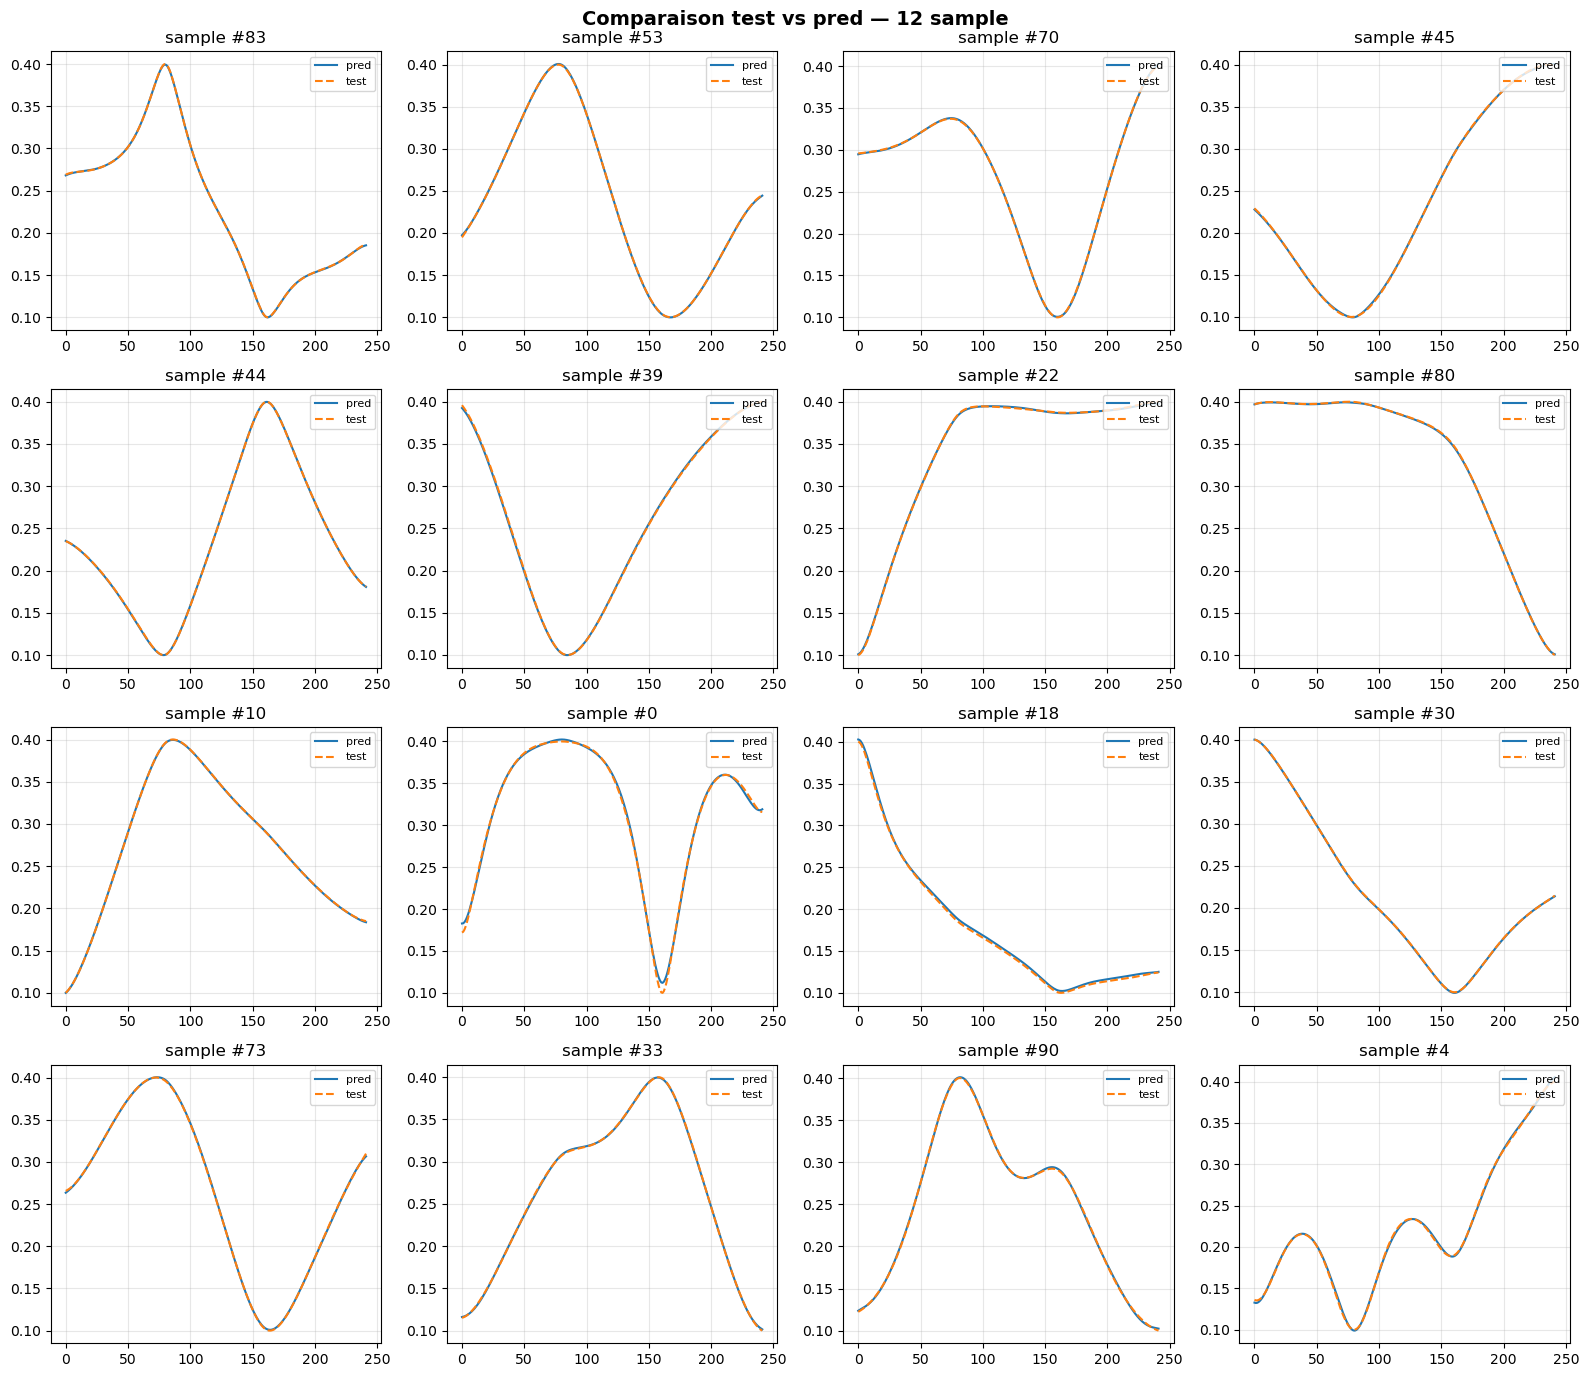

In [32]:
# ==============================
# VISUALISATION: 16 random test samples
# ==============================
sel = np.random.choice(len(Y_test_real), 16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, k in zip(axes.flatten(), sel):
    ax.plot(t, Y_pred[k], label='predicted')
    ax.plot(t, Y_test_real[k], '--', label='true')
    ax.set_title(f'test sample #{k}')
    ax.set_xlabel('t'); ax.set_ylabel('$C_0$')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.3)

fig.suptitle('Test set: true vs predicted $C_0$ (16 random samples)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'test_samples.png', dpi=150, bbox_inches='tight')
plt.show()

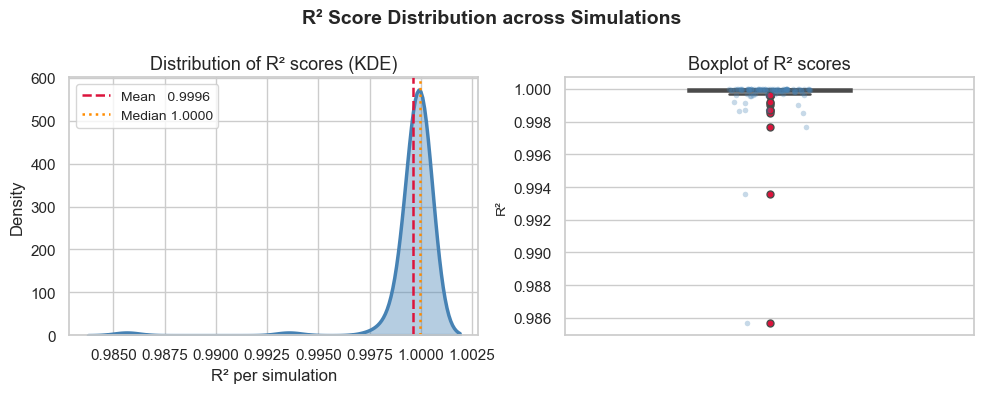

In [33]:
# Distribution of R² per simulation 
r2_par_simulation = [
    r2_score(Y_test_real[i], Y_pred[i]) 
    for i in range(len(Y_test))
]

sns.set_theme(style="whitegrid", palette="muted")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# --- KDE / PDF ---
sns.kdeplot(
    r2_par_simulation,
    ax=axes[0],
    fill=True,
    color="steelblue",
    linewidth=2.5,
    alpha=0.4,
)
axes[0].axvline(np.mean(r2_par_simulation),   color='crimson',   lw=1.8, ls='--', label=f'Mean   {np.mean(r2_par_simulation):.4f}')
axes[0].axvline(np.median(r2_par_simulation), color='darkorange', lw=1.8, ls=':',  label=f'Median {np.median(r2_par_simulation):.4f}')
axes[0].set_xlabel('R² per simulation', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].set_title('Distribution of R² scores (KDE)', fontsize=13)
axes[0].legend(fontsize=10)

# --- Boxplot + strip ---
sns.boxplot(
    y=r2_par_simulation,
    ax=axes[1],
    color="steelblue",
    width=0.4,
    linewidth=1.8,
    flierprops=dict(marker='o', markerfacecolor='crimson', markersize=5),
)
sns.stripplot(
    y=r2_par_simulation,
    ax=axes[1],
    color="steelblue",
    alpha=0.3,
    size=4,
    jitter=True,
)
axes[1].set_ylabel('R²', fontsize=10)
axes[1].set_title('Boxplot of R² scores', fontsize=13)
axes[1].set_xticks([])

plt.suptitle('R² Score Distribution across Simulations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'r2_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Inverse Design for the Target Profiles

The trained pipeline is applied to each target $Q^{\star}$ to obtain the injection profile $C_0$. Predicted profiles are saved to text files and then simulated with the process model.

In [34]:
def predict_C(Q_profile, scaler_X, pca_x, mlp, pca_y, scaler_Y):
    """Inverse map: target distribution Q(x) -> injection concentration C_0(t)."""
    Q = Q_profile.reshape(1, -1)
    Q_scaled = scaler_X.transform(Q)
    Q_pca = pca_x.transform(Q_scaled)
    C_pca = mlp(Q_pca)
    C_opt = pca_y.inverse_transform(C_pca)
    return scaler_Y.inverse_transform(C_opt).reshape(-1)

# Predicted C_0 for each target, saved to be simulated with the CRTM solver
C_opt = {}
for name, c_file in zip(names, C_list):
    C_opt[name] = predict_C(targets[name]['Q'], scaler_X, pca_x, mlp, pca_y, scaler_Y)
    np.savetxt(c_file, C_opt[name])
    print(f"{name:6s} -> {c_file}")

UD     -> CUD.txt
FG-O   -> CFGO.txt
FG-X   -> CFGX.txt
FG-NI  -> CFGNI.txt
FG-XO  -> CFGOX.txt
FG-OX  -> CFGXO.txt


### 7.1 Position of the targets in the input space of the network (PCA of Q)

For each target:
- **relative PCA residual**: fraction of the (standardised) target not captured by the $k_x$ retained modes, compared with its distribution over the test set;
- **max |z|/σ**: largest latent coordinate, in units of the training standard deviation of that mode.

Values within the test-set range mean the network is used in **interpolation**.

Jeu de test — résidu PCA : médiane 1.26e-03, max 1.07e-02 | max|z|/σ : médiane 1.84, max 4.18



,résidu PCA,percentile test (%),max |z|/σ,percentile test (%)
UD,1.28e-03,51.0,2.19,71.0
FG-O,3.05e-03,86.0,1.61,34.0
FG-X,3.39e-03,86.0,2.25,72.0
FG-NI,5.82e-03,98.0,2.73,82.0
FG-XO,3.47e-03,86.0,2.08,67.0
FG-OX,1.24e-03,49.0,2.35,75.0


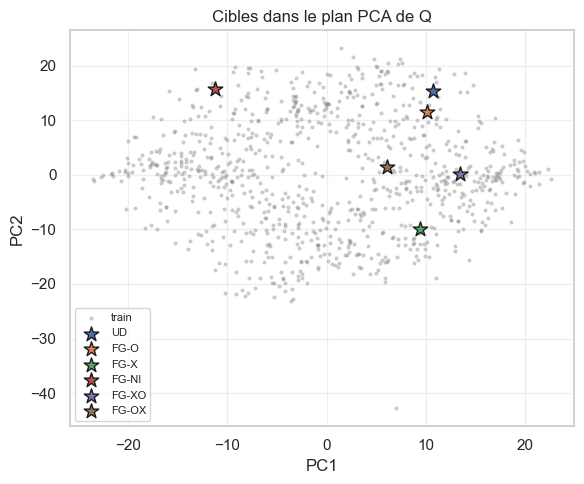

In [35]:
def pca_diagnostics(Q_rows):
    Qs   = scaler_X.transform(np.atleast_2d(Q_rows))
    z    = pca_x.transform(Qs)
    rec  = pca_x.inverse_transform(z)
    res  = np.linalg.norm(Qs - rec, axis=1) / np.linalg.norm(Qs, axis=1)
    zmax = np.max(np.abs(z) / np.sqrt(pca_x.explained_variance_), axis=1)
    return res, zmax, z

res_test, zmax_test, _ = pca_diagnostics(scaler_X.inverse_transform(X_test))
print(f"Test set — PCA residual: median {np.median(res_test):.2e}, max {res_test.max():.2e} | "
      f"max|z|/σ: median {np.median(zmax_test):.2f}, max {zmax_test.max():.2f}\n")

rows, z_targets = [], {}
for name in names:
    r, zm, z = pca_diagnostics(targets[name]['Q'])
    z_targets[name] = z[0]
    rows.append([r[0], np.mean(res_test <= r[0]) * 100, zm[0], np.mean(zmax_test <= zm[0]) * 100])
df_pca = pd.DataFrame(rows, index=names,
                      columns=['PCA residual', 'test percentile (%)', 'max |z|/σ', 'test percentile (%) '])
display(df_pca.style.format({'PCA residual': '{:.2e}', 'test percentile (%)': '{:.1f}',
                             'max |z|/σ': '{:.2f}', 'test percentile (%) ': '{:.1f}'}))

# Latent coordinates of the targets vs training cloud (modes 1-2)
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2', '#937860']
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(x_train[:, 0], x_train[:, 1], s=4, c='grey', alpha=0.3, label='train')
for n, c in zip(names, colors):
    ax.scatter(z_targets[n][0], z_targets[n][1], s=120, marker='*', color=c, edgecolor='k', label=n)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title('Targets in the PCA plane of Q')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'targets_pca_plane.png', dpi=150, bbox_inches='tight'); plt.show()

### 7.2 Range of the predicted $C_0$ vs range of the training $C_0$

In [36]:
C0_min, C0_max = C_0.min(), C_0.max()
C0_lo, C0_hi   = C_0.min(axis=0), C_0.max(axis=0)       # point-wise envelope in t
print(f"Training C_0: min = {C0_min:.4f} | max = {C0_max:.4f}\n")
for name in names:
    c = C_opt[name]
    out = np.mean((c < C0_lo) | (c > C0_hi)) * 100
    print(f"{name:6s}  min = {c.min():.4f}  max = {c.max():.4f}  | outside training envelope: {out:5.1f} % of time steps")

C_0 dataset : min = 0.1000 | max = 0.4000

UD      min = 0.2158  max = 0.4561  | hors enveloppe dataset :  23.1 % des instants
FG-O    min = 0.0594  max = 0.3537  | hors enveloppe dataset :   6.6 % des instants
FG-X    min = 0.1430  max = 0.4403  | hors enveloppe dataset :   7.0 % des instants
FG-NI   min = 0.2329  max = 0.4203  | hors enveloppe dataset :  18.2 % des instants
FG-XO   min = 0.1108  max = 0.3859  | hors enveloppe dataset :   0.0 % des instants
FG-OX   min = 0.0629  max = 0.4451  | hors enveloppe dataset :  18.6 % des instants


## 8. Validation by Re-simulation

The predicted $C_0$ profiles are fed back to the CRTM simulator. The resulting distributions $Q$ are compared with the targets (left: predicted $C_0$; centre: target vs re-simulated $Q$; right: relative error).

The re-simulated distributions are read from `data/resimulated/` (one file per target, produced by the CRTM solver from the files in `results/predicted_C0/`).

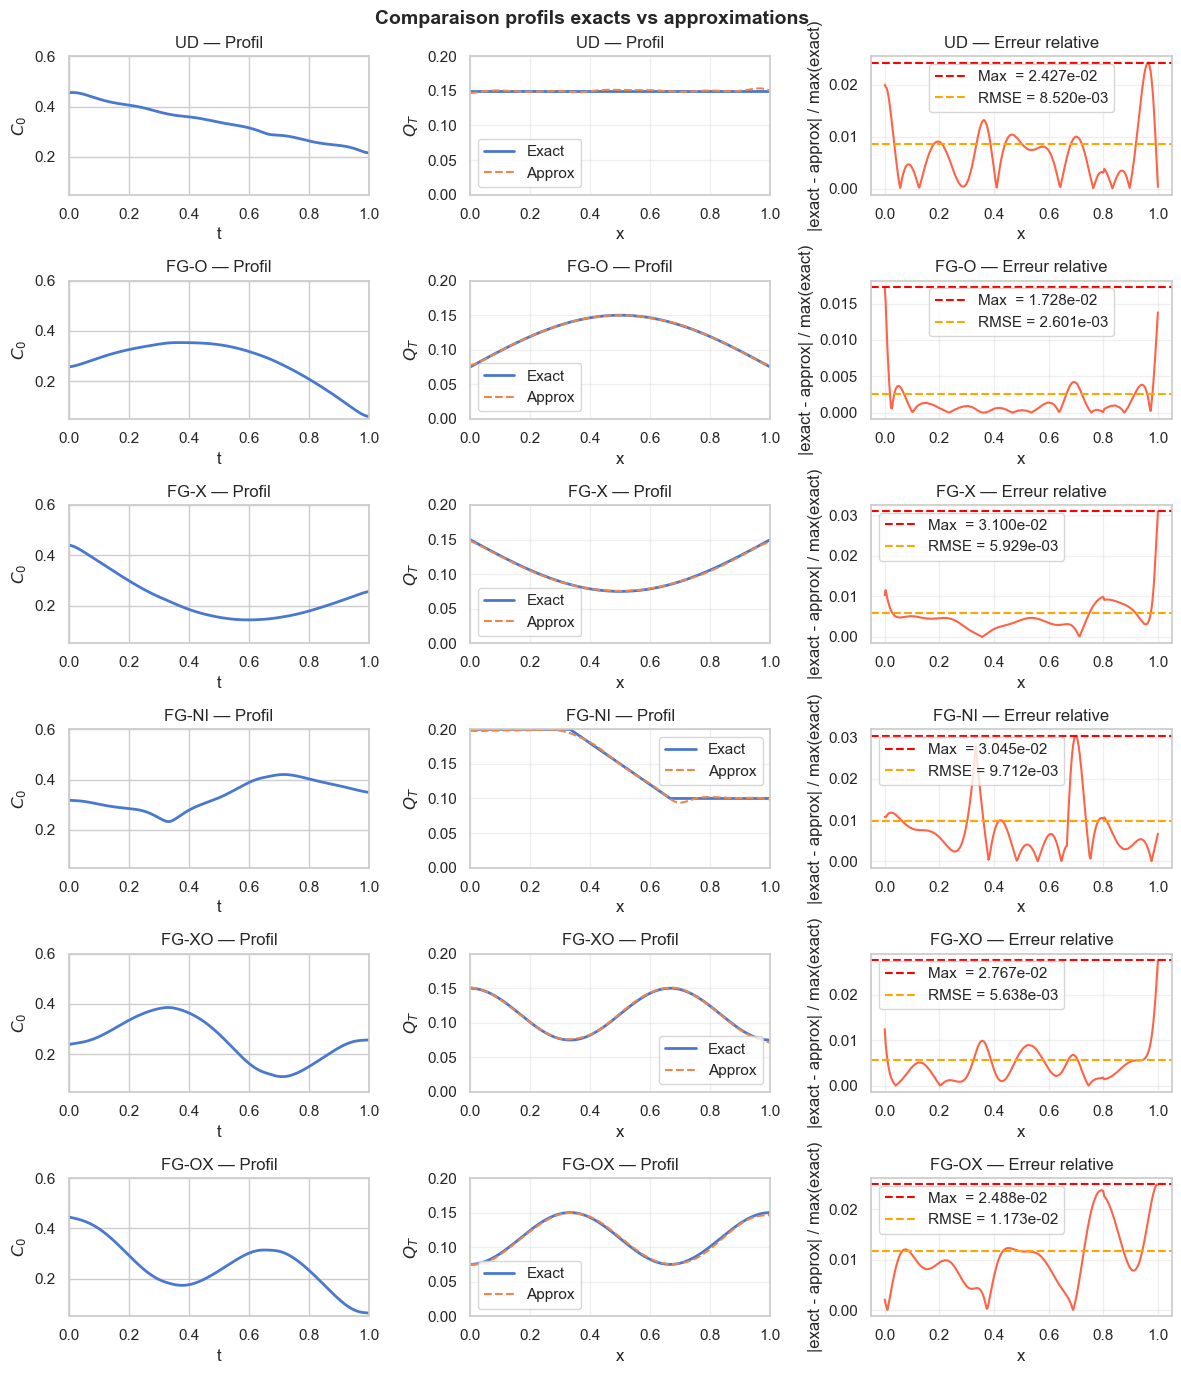

In [37]:
# Re-simulated Q (CRTM solver run on the predicted C_0 files)
approx_Qprofiles = [np.loadtxt(f) for f in Q_list]

C_pred = [np.loadtxt(f) for f in C_list]

# --- Figure ---
fig, axes = plt.subplots(6, 3, figsize=(12, 14))
fig.suptitle('Target vs re-simulated distributions', fontsize=14, fontweight='bold')

for i, (exact, approx, Cpred, name) in enumerate(zip(exact_profiles, approx_Qprofiles, C_pred, names)):
    err = np.abs(exact - approx) / np.max(exact)   # relative error
    rmse = np.sqrt(np.mean((exact - approx)**2)) / np.max(exact) 
    max_e = np.max(np.abs(exact - approx)) / np.max(exact) 
    ax0 = axes[i, 0]
    ax0.plot(t, Cpred,  linewidth=2)
    ax0.set_title(f'{name} — predicted $C_0$')
    ax0.set_xlim(0, 1)
    ax0.set_ylim(0.05, 0.6)
    ax0.set_xlabel('t')
    ax0.set_ylabel('$C_0$')
    
    ax1 = axes[i, 1]
    ax1.plot(x, exact,  label='Target',  linewidth=2)
    ax1.plot(x, approx, label='Re-simulated', linewidth=1.5, linestyle='--')
    ax1.set_title(f'{name} — $Q$')
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 0.2)
    ax1.set_xlabel('x')
    ax1.set_ylabel('$Q_T$')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2 = axes[i, 2]
    ax2.plot(x, err, color='tomato', linewidth=1.5)
    ax2.axhline(max_e,  color='red',    linestyle='--',
                label=f'Max  = {max_e:.3e}')
    ax2.axhline(rmse, color='orange', linestyle='--',
                label=f'RMSE = {rmse:.3e}')
    ax2.set_title(f'{name} — relative error')
    ax2.set_xlabel('x')
    ax2.set_ylabel('|Q* - Q| / max(Q*)')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'target_vs_resimulated.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Inverse network vs nearest neighbour of the dataset

Since $Q$ and $C_0$ take values in $(0,1)$, profiles are compared with **relative** L2 errors $\|Q - Q^{\star}\| / \|Q^{\star}\|$. For each target:
- `NN dataset (%)`: relative distance between the target and the closest simulated $Q$ of the dataset — what one would obtain by simply picking the best existing $C_0$;
- `MLP re-simulated (%)`: relative distance between the target and the $Q$ re-simulated with the $C_0$ predicted by the network;
- `gain = NN / MLP` (> 1: the network outperforms the best sample of the dataset);
- `ΔC_0 vs NN (%)`: relative difference between the predicted $C_0$ and the $C_0$ of the nearest neighbour.

,d_NN (dataset),err MLP (re-simulé),gain,err MLP relative (%)
UD,2.6213e-01,2.2173e-02,11.82,0.852
FG-O,1.7005e-01,6.7692e-03,25.12,0.313
FG-X,1.4893e-01,1.5431e-02,9.65,0.847
FG-NI,3.1968e-01,3.3700e-02,9.49,1.242
FG-XO,1.0408e-01,1.4671e-02,7.09,0.732
FG-OX,1.9997e-01,3.0531e-02,6.55,1.522


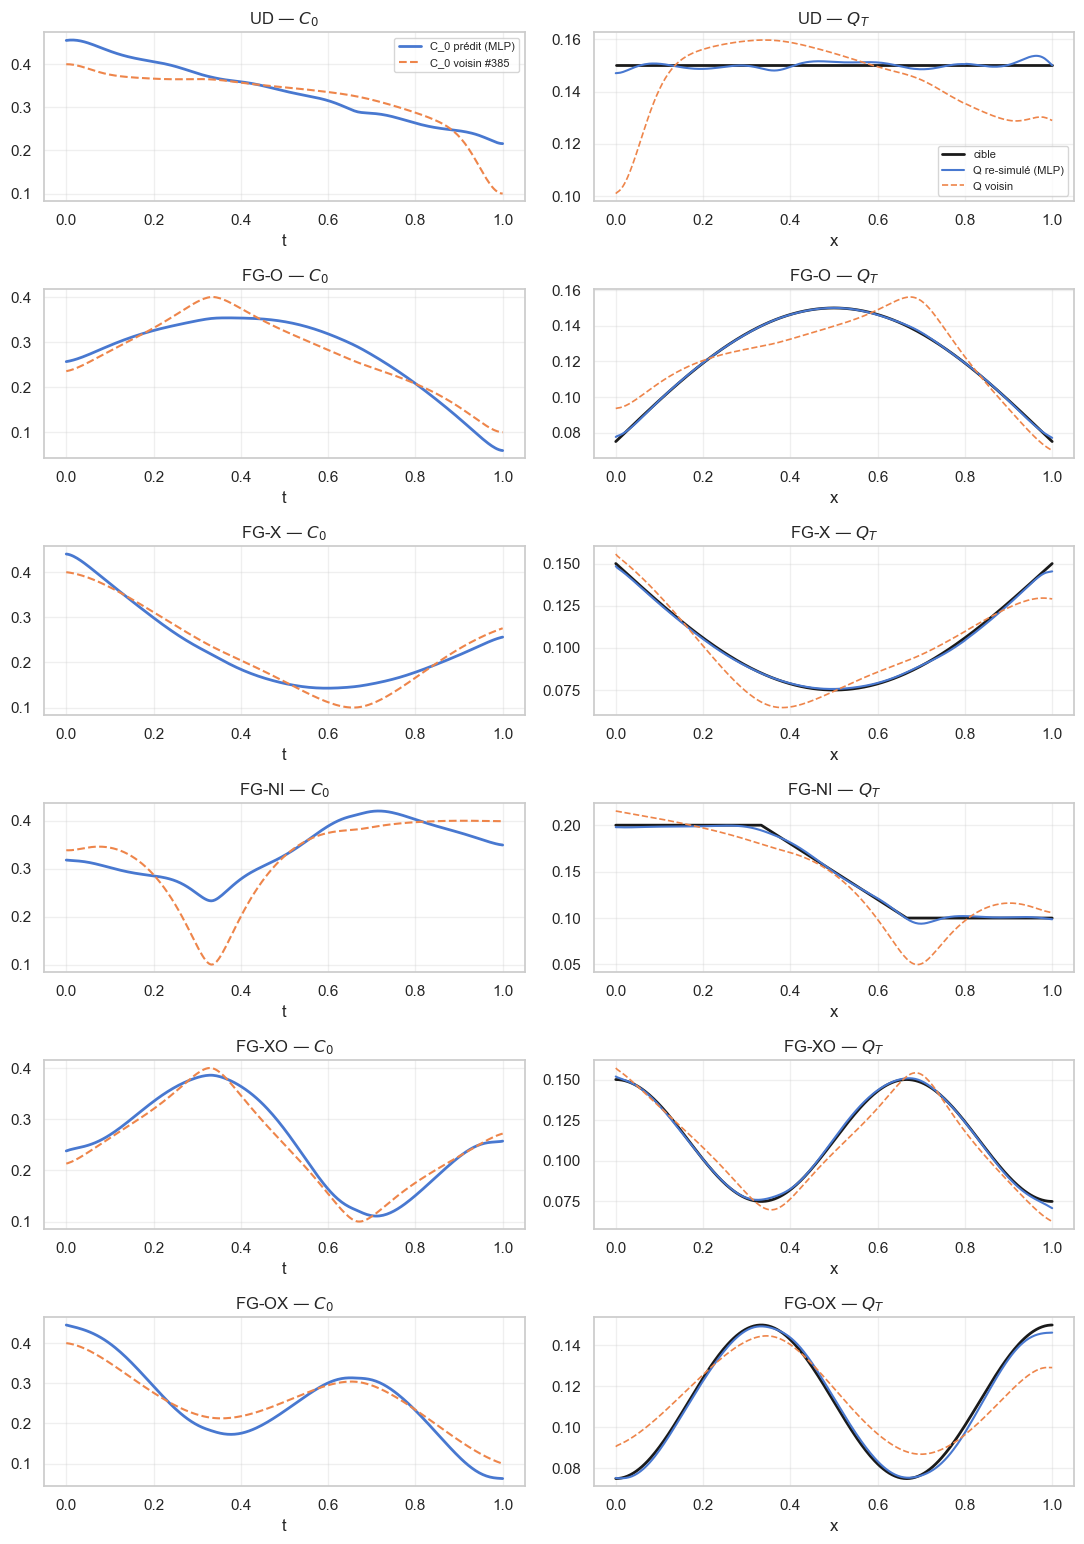

In [39]:
rows = []
for name, q_res in zip(names, approx_Qprofiles):
    q_t   = targets[name]['Q']
    j     = idx_nn_target[name]
    e_mlp = np.linalg.norm(q_res - q_t) / np.linalg.norm(q_t)
    d_nn  = d_min_target[name]
    dC    = np.linalg.norm(C_opt[name] - C_0[j]) / np.linalg.norm(C_opt[name])
    rows.append([100 * d_nn, 100 * e_mlp, d_nn / e_mlp, 100 * dC])
df_cmp = pd.DataFrame(rows, index=names,
                      columns=['NN dataset (%)', 'MLP re-simulated (%)', 'gain', 'ΔC_0 vs NN (%)'])
display(df_cmp.style.format({'NN dataset (%)': '{:.2f}', 'MLP re-simulated (%)': '{:.3f}',
                             'gain': '{:.1f}', 'ΔC_0 vs NN (%)': '{:.1f}'}))

# Predicted C_0 vs nearest-neighbour C_0, and corresponding Q
fig, axes = plt.subplots(len(names), 2, figsize=(11, 2.6 * len(names)))
for i, (name, q_res) in enumerate(zip(names, approx_Qprofiles)):
    j = idx_nn_target[name]
    axes[i, 0].plot(t, C_opt[name], lw=2, label='predicted $C_0$ (MLP)')
    axes[i, 0].plot(t, C_0[j], lw=1.5, ls='--', label=f'nearest-neighbour $C_0$ (#{j})')
    axes[i, 0].set_title(f'{name} — $C_0$'); axes[i, 0].set_xlabel('t'); axes[i, 0].grid(alpha=0.3)
    axes[i, 1].plot(x, targets[name]['Q'], 'k', lw=2, label='target')
    axes[i, 1].plot(x, q_res, lw=1.5, label='re-simulated (MLP)')
    axes[i, 1].plot(x, Q_p[j], lw=1.2, ls='--', label='nearest neighbour')
    axes[i, 1].set_title(f'{name} — $Q$'); axes[i, 1].set_xlabel('x'); axes[i, 1].grid(alpha=0.3)
    if i == 0:
        axes[i, 0].legend(fontsize=8); axes[i, 1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / 'mlp_vs_nearest_neighbour.png', dpi=150, bbox_inches='tight'); plt.show()

## 10. Conclusion

A purely data-driven inverse model was built to identify the injection concentration $C_0(t)$ that produces a prescribed particle distribution $Q(x)$ in CRTM. The approach learns the inverse map directly, so a new target is solved in a single forward pass, with no optimisation loop at inference.

**Main results**
- **Test set:** RMSE = 0.00151, MAE = 0.00078, $R^2$ = 0.99973 on $C_0$.
- **Target profiles (re-simulation):** the $Q$ obtained with the predicted $C_0$ match the six targets with a relative L2 error between **0.3 % and 1.5 %**.
- **Beyond the dataset:** for every target, the network outperforms the closest simulation of the dataset by a factor of **6.5 to 25**: relative error of 5–12 % for the best dataset sample vs 0.3–1.5 % for the network. The network does not retrieve an existing sample; it constructs new injection profiles.
- **Interpolation regime:** in the PCA space of $Q$, all targets lie within the training distribution (PCA residual and latent coordinates within the test-set range).

**Observations and perspectives**
- The remaining error is concentrated at the boundaries $x=0$ and $x=1$, and at the slope discontinuities of FG-NI, a non-smooth target approximated from smooth Gaussian-process data.
- Some predicted $C_0$ slightly exceed the range of the training profiles ($[0.10, 0.40]$), mainly near $t=0$ and $t=1$. Re-simulation confirms that these profiles produce the expected distributions; their physical feasibility can be secured by widening the range of the Gaussian-process sampling if needed.
- The same framework can be applied directly to any other target distribution, or extended to additional process parameters.